<div style="box-sizing:border-box;max-width:100%;margin:0 0 8px;padding:4px 0;color:inherit;line-height:1.35;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:52px!important;max-width:52px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;"><div style="display:flex;align-items:center;justify-content:space-between;flex-wrap:wrap;gap:8px 12px;"><span style="min-width:0;color:inherit;font-size:12px;font-weight:700;letter-spacing:0.055em;text-transform:uppercase;"><a href="https://thetahat.ru/courses/ysda-group" style="color:inherit;text-decoration:none;">Школа анализа данных</a>&nbsp;·&nbsp;Машинное обучение</span></div></div>

<h2><span style="display:block;box-sizing:border-box;max-width:100%;padding:16px 22px 17px;border-radius:14px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 50%,#B316B8 100%);color:#FFFFFF;line-height:1.15;font-weight:500;">Домашнее задание 9. Градиентный бустинг.</span></h2>

<div style="box-sizing:border-box;max-width:100%;margin:18px 0 26px;padding:18px 20px;border:1px solid rgba(127, 127, 127, 0.28);border-left:4px solid #F13A3F;border-radius:12px;background:rgba(127, 127, 127, 0.07);color:inherit;">
  <div style="color:inherit;font-size:12px;font-weight:800;letter-spacing:0.08em;text-transform:uppercase;">Общие правила</div>
  <ul style="margin:10px 0 0;padding-left:22px;line-height:1.55;">
    <li>Выполненную работу <strong>в формате <code>ipynb</code></strong> нужно отправить в кабинете студента <a href="https://thetahat.ru/"><strong>на сайте ThetaHat</strong></a>. Инструкция по регистрации на сайте, записи на курс и сдаче домашек есть на странице курса в ЛМС. <strong>Работы, присланные иным способом, не принимаются.</strong> Дедлайны указаны в личном кабинете, они являются строгими.</li>
    <li>Обязательно изучите <a href="https://thetahat.ru/courses/design-hw"><strong>руководство по оформлению ДЗ</strong></a>. В частности, оно содержит примеры случаев, когда могут быть снижены баллы.</li>
    <li>Обратите внимание на <a href="https://thetahat.ru/courses/ai-rules"><strong>правила использования ИИ-инструментов</strong></a> при решении домашнего задания.</li>
    <li>Выполнять задание необходимо полностью самостоятельно. <strong>При обнаружении списывания (в т.ч. злоупотребление ИИ) всем участникам списывания дается штраф согласно правилам на странице курса.</strong></li>
    <li>Решение проверяется системой ИИ-проверки <a href="https://thetahat.ru/thetagrader"><img src="https://thetahat.ru/images/ai_eval_small.png" style="display:inline;vertical-align:middle;" alt="ThetaGrader"></a> <a href="https://thetahat.ru/thetagrader"><strong>ThetaGrader</strong></a>. Результаты проверки будут отправлены вам в течение 1-2 суток после дедлайна. После вы можете исправить ошибки или аргументировать свое мнение и отправить на проверку проверяющему. Подробнее на странице курса в ЛМС.</li>
    <li>Никакой код из данного задания при проверке запускаться не будет. <em>Если код не выполнен, недописан и т.д., то он не оценивается.</em></li>
  </ul>
  </br>
    
  <div style="color:inherit;font-size:12px;font-weight:800;letter-spacing:0.08em;text-transform:uppercase;">Правила заполнения ноутбука</div>
  <ul style="margin:8px 0 0;padding-left:22px;line-height:1.55;">
    <li>Запрещается удалять имеющиеся в ноутбуке ячейки, менять местами положения существующих ячеек.</li>
    <li>Отвечайте на вопросы, а также добавляйте новые ячейки в любом количестве в предложенных местах, которые обозначены <code>&lt;...&gt;</code>.</li>
    <li>Сохраняйте естественный линейный порядок повествования в ноутбуке сверху-вниз. Комментарии к решению пишите в markdown-ячейках. Выполнение задания (ход решения, выводы и пр.) должно быть осуществлено на русском языке.</li>
    <li>В markdown-ячейках, содержащих описание задачи, находятся специальные отметки, которые <strong style="color:red;">запрещается модифицировать</strong>.</li>
    <li>Решение теоретических задач оформляйте в markdown-ячейках в формате $\LaTeX$. При решении можно использовать ИИ-инструменты для оформления написанного самостоятельно решения, например, написать черновик формул и попросить ИИ оформить эти формулы в $\LaTeX$.</li>
    <li>При нарушении данных правил работа может получить 0 баллов.</li>
  </ul>
</div>

## 🔵 <font color="blue">Часть L</font>

Дедлайн по части M во вторник 17.11 в 16:00. Дедлайн по этой части **в субботу 21.11 в 23:59**. Подробнее в описании курса в ЛМС.


**Баллы эту часть задания:**

* Задача 3 &mdash; 100 баллов.

In [32]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score, 
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
    root_mean_squared_error,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", palette="Set2", font_scale=1.2)

In [2]:
# Bot check

# HW_ID: ysda_ml1_task_l9
# Система проверит этот ID и предупредит, если случайно сдать что-то не то.

# Status: final
# Перед отправкой в финальном решении удали "not" в строчке выше.
# Так система проверит, что ты ничего не перепутал, и отправляешь финальную версию,
# а не промежуточную. После отправки работы со статусом final до дедлайна все
# еще можно вносить исправления и отправлять повторно.

# Никакие значения в этой ячейке не влияют на факт сдачи работы.

---

### Ссылки на использование ИИ

Если при решении задач использовался ИИ, укажи здесь публичные ссылки на все чаты с ИИ и поясни, для каких целей он применялся. Обрати внимание на <a href="https://thetahat.ru/courses/ai-rules" target="_top">правила</a>.

**Задача 1**
1. ссылка
    - для чего использована
    - для чего использована
2. ссылка
    - для чего использована

**Задача 2**
1. ссылка
    - для чего использована


---
### <span style="display:inline-block;padding:6px 13px;border-radius:999px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 55%,#B316B8 100%);color:#FFFFFF;font-size:16px;font-weight:700;line-height:1.2;">Задача 3</span>

**Внимание!** Перед выполнением задачи прочитайте полностью условие. В задаче используются смеси различных моделей с разными гиперпараметрами. Подумайте над тем, какой гиперпараметр как подбирать и на каком множестве. Не забудьте, что на тестовой выборке, по которой делаются итоговые выводы, ничего не должно обучаться.

Будем рассматривать данные из задачи 2 задания 8.

**Не забывайте делать выводы в каждом пункте!**

**1.** Загрузите данные и разбейте их на train и test, выделив на test 25% данных.

In [3]:
import kagglehub

path = kagglehub.dataset_download("camnugent/california-housing-prices")
data = pd.read_csv(Path(path) / "housing.csv")
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
data = data[~data.isna().any(axis=1)]

In [5]:
ocean_proximity_values = ["ISLAND", "NEAR OCEAN", "NEAR BAY", "<1H OCEAN", "INLAND"]
data["ocean_proximity_num"] = data["ocean_proximity"].apply(
    lambda value: ocean_proximity_values.index(value)
)

In [6]:
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,ocean_proximity_num
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,2
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,2
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,2
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,2
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,2


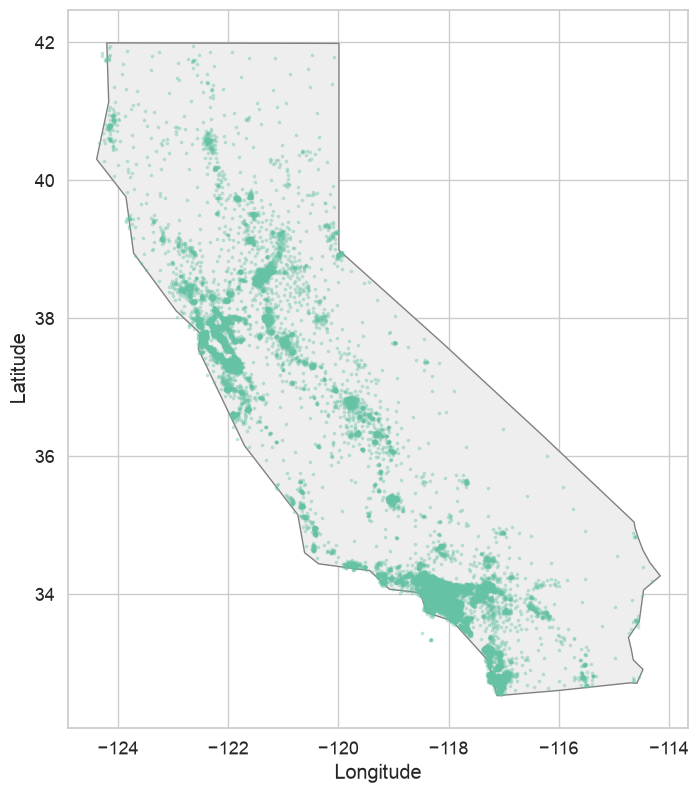

In [7]:
import geopandas as gpd
import matplotlib.pyplot as plt

url = (
    "https://raw.githubusercontent.com/nvkelso/"
    "natural-earth-vector/master/geojson/ne_110m_admin_1_states_provinces.geojson"
)
states = gpd.read_file(url)
california = states[states["name"] == "California"]

fig, ax = plt.subplots(figsize=(8, 10))
california.plot(ax=ax, color="#eeeeee", edgecolor="gray")

ax.scatter(
    data["longitude"],
    data["latitude"],
    s=3,
    alpha=0.3,
)
ax.set_aspect(1 / np.cos(np.deg2rad(37)))
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()

In [8]:
data_train, data_test = train_test_split(
    data, test_size=0.25, random_state=RANDOM_STATE
)
X_num_train = data_train.drop(columns=["median_house_value", "ocean_proximity"])
X_cat_train = data_train.drop(columns=["median_house_value", "ocean_proximity_num"])
X_test_num = data_test.drop(columns=["median_house_value", "ocean_proximity"])
X_test_cat = data_test.drop(columns=["median_house_value", "ocean_proximity_num"])
y_train = data_train["median_house_value"]
y_test = data_test["median_house_value"]

Вывод: ну, мы успешно использовали датасет из прошлого задания, такой вот вывод...

**2.** Для градиентного бустинга исследуйте, как меняется качество модели в зависимости от значений гиперпараметров и сделайте выводы по результатам. Гиперпараметры:
* количество деревьев (`n_estimators`) [от 1 до 1000];
* максимальная глубина дерева (`max_depth`) [от 1 до 15];
* скорость обучения (`learning_rate`), поясните также необходимость этого гиперпараметра.

Рассмотрите следующие реализации градиентного бустинга:
* `GradientBoostingRegressor` из `sklearn`,
* XGBoost,
* CatBoost с передачей *исходных* категориальных признаков через указание `cat_features`.
    
Сравните со случайным лесом результаты зависимости метрики по количеству деревьев и по максимальной глубине дерева.

*Замечания.*
* В качестве основы можно использовать свое решение задания 7. В части случаев нужно только заменить `RandomForestRegressor` на аналогичные имена реализаций бустинга.
* При сравнении методов по одинаковым свойствам желательно рисовать результаты на одном графике.
* Обратите внимание на метод `staged_predict` у `GradientBoostingRegressor`. Он позволяет получить "кумулятивные" предсказания, то есть по первым $t$ деревьям по всем значениям $t$, что может значительно ускорить выполнение кода. Для XGBoost и CatBoost аналогичную операцию можно выполнить, передав в функцию `predict` параметры `iteration_range` и `ntree_end` соответственно.
* При желании, границы рассмотрения значений гиперпараметров можно увеличить.

In [9]:
from catboost import CatBoostRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from xgboost import XGBRegressor

from collections.abc import Iterator
from numpy.typing import NDArray
type Regressor = GradientBoostingRegressor | XGBRegressor | CatBoostRegressor | RandomForestRegressor

In [10]:
BASELINE_TREES = 100
BASELINE_DEPTH = 6
BASELINE_RATE = 0.1

fit_idx, val_idx = train_test_split(np.arange(len(y_train)), test_size=0.2, random_state=RANDOM_STATE)
y_fit, y_val = y_train.iloc[fit_idx], y_train.iloc[val_idx]

tree_counts = (
    np.r_[
        np.geomspace(1, BASELINE_TREES, 10),
        np.geomspace(BASELINE_TREES, 10000, 10)[1:],
    ]
    .round()
    .astype(int)
    .tolist()
)
depths = range(1, 17)
rates = np.geomspace(0.01, 1.0, 10).tolist()

boosters = ["sklearn GB", "XGBoost", "CatBoost"]
models = [*boosters, "Random Forest"]

In [11]:
def fit_model(
    model_name: str,
    *,
    n_estimators: int = BASELINE_TREES,
    max_depth: int = BASELINE_DEPTH,
    learning_rate: float = BASELINE_RATE,
) -> tuple[Regressor, pd.DataFrame]:
    params = {
        "n_estimators": n_estimators,
        "max_depth": max_depth,
        "random_state": RANDOM_STATE,
    }

    estimator: Regressor
    if model_name == "CatBoost":
        estimator = CatBoostRegressor(
            **params,
            learning_rate=learning_rate,
            cat_features=["ocean_proximity"],
            verbose=False,
            allow_writing_files=False,
        )
        features = X_cat_train
    else:
        features = X_num_train
        if model_name == "sklearn GB":
            estimator = GradientBoostingRegressor(**params, learning_rate=learning_rate)
        elif model_name == "XGBoost":
            estimator = XGBRegressor(**params, learning_rate=learning_rate)
        else:
            estimator = RandomForestRegressor(**params, n_jobs=-1)

    estimator.fit(features.iloc[fit_idx], y_fit)
    return estimator, features.iloc[val_idx]

In [12]:
def prefix_predictions(
    estimator: Regressor, features_val: pd.DataFrame, counts: list[int]
) -> Iterator[tuple[int, NDArray[np.floating]]]:
    wanted = set(counts)
    if isinstance(estimator, GradientBoostingRegressor):
        for count, predictions in enumerate(estimator.staged_predict(features_val), start=1):
            if count in wanted:
                yield count, predictions
    elif isinstance(estimator, XGBRegressor):
        for count in counts:
            yield count, estimator.predict(features_val, iteration_range=(0, count))
    elif isinstance(estimator, CatBoostRegressor):
        for count in counts:
            yield count, estimator.predict(features_val, ntree_end=count)
    else:
        features_array = features_val.to_numpy(dtype=np.float32)
        pred_sum = np.zeros(len(features_val))
        for count, tree in enumerate(estimator.estimators_, start=1):
            pred_sum += tree.predict(features_array)
            if count in wanted:
                yield count, pred_sum / count

In [13]:
rows: list[dict[str, str | int | float]] = []

def record(sweep: str, model_name: str, predictions: NDArray[np.floating], value: float) -> None:
    """Record validation MSE with the swept value and fixed defaults."""
    row: dict[str, str | int | float] = {
        "sweep": sweep,
        "model": model_name,
        "n_estimators": BASELINE_TREES,
        "max_depth": BASELINE_DEPTH,
        "learning_rate": BASELINE_RATE if model_name in boosters else np.nan,
        "MSE": mean_squared_error(y_val, predictions),
    }
    row[sweep] = value
    rows.append(row)

In [14]:
with tqdm(models, desc="Модели") as model_progress:
    for name in model_progress:
        model_progress.set_postfix_str(name)
        model, x_val = fit_model(name, n_estimators=max(tree_counts))
        tree_predictions = dict(prefix_predictions(model, x_val, tree_counts))
        baseline_pred = tree_predictions[BASELINE_TREES]

        for n, pred in tree_predictions.items():
            record("n_estimators", name, pred, n)

        for depth in tqdm(depths, desc="max_depth", leave=False):
            if depth == BASELINE_DEPTH:
                pred = baseline_pred
            else:
                model, x_val = fit_model(name, max_depth=depth)
                pred = model.predict(x_val)
            record("max_depth", name, pred, depth)

        if name in boosters:
            for rate in tqdm(rates, desc="learning_rate", leave=False):
                if rate == BASELINE_RATE:
                    pred = baseline_pred
                else:
                    model, x_val = fit_model(name, learning_rate=rate)
                    pred = model.predict(x_val)
                record("learning_rate", name, pred, rate)

results = pd.DataFrame(rows)

Модели:   0%|          | 0/4 [00:00<?, ?it/s]

max_depth:   0%|          | 0/16 [00:00<?, ?it/s]

learning_rate:   0%|          | 0/10 [00:00<?, ?it/s]

max_depth:   0%|          | 0/16 [00:00<?, ?it/s]

learning_rate:   0%|          | 0/10 [00:00<?, ?it/s]

max_depth:   0%|          | 0/16 [00:00<?, ?it/s]

learning_rate:   0%|          | 0/10 [00:00<?, ?it/s]

max_depth:   0%|          | 0/16 [00:00<?, ?it/s]

In [15]:
results

,sweep,model,n_estimators,max_depth,learning_rate,MSE
0,n_estimators,sklearn GB,1,6,0.1,1.173900e+10
1,n_estimators,sklearn GB,2,6,0.1,1.032496e+10
2,n_estimators,sklearn GB,3,6,0.1,9.117605e+09
3,n_estimators,sklearn GB,5,6,0.1,7.369750e+09
4,n_estimators,sklearn GB,8,6,0.1,5.749240e+09
...,...,...,...,...,...,...
165,max_depth,Random Forest,100,12,NaN,2.569573e+09
166,max_depth,Random Forest,100,13,NaN,2.494635e+09
167,max_depth,Random Forest,100,14,NaN,2.455525e+09
168,max_depth,Random Forest,100,15,NaN,2.423372e+09


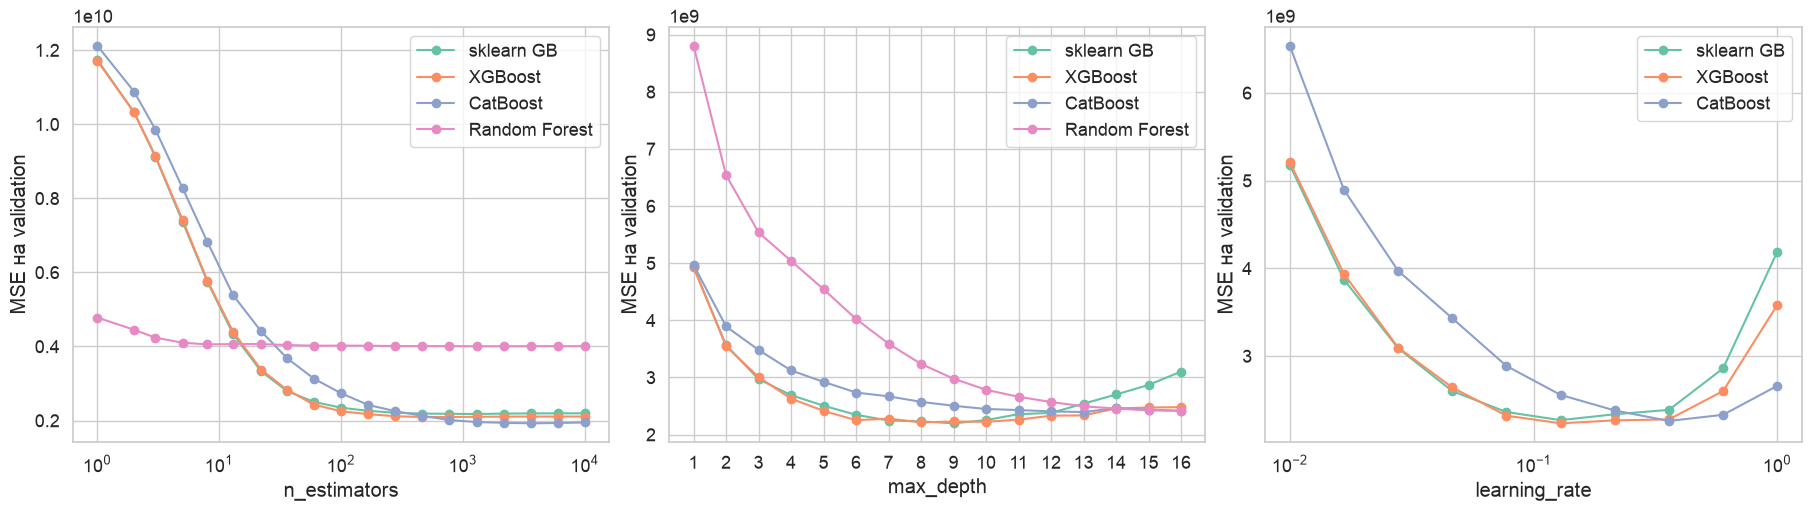

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), layout="constrained")
for ax, param in zip(axes, ["n_estimators", "max_depth", "learning_rate"], strict=True):
    for name, group in results[results["sweep"].eq(param)].groupby("model", sort=False):
        sorted_group = group.sort_values(param)
        ax.plot(sorted_group[param], sorted_group["MSE"], marker="o", label=name)

    ax.set(xlabel=param, ylabel="MSE на validation")
    if param in ("n_estimators", "learning_rate"):
        ax.set_xscale("log")
    else:
        ax.set_xticks(list(depths))
    ax.legend()

plt.show()

Какая модель бустинга показывает наилучшие результаты? Для дальнейших экспериментов используйте эту модель.

Лучше всего себя показывает XGBoost и GradientBoostingRegressor, хотя на предельных значениях их догоняет CatBoost.  
Возьму XGBoost, т.к. он достигает оптимум на меньшем числе деревьев и глубине и немного обгоняет sklearn при оценке MSE для learning rate.  

**3.** Подберите оптимальные гиперпараметры выбранной реализации градиентного бустинга с помощью кросс-валидации методом случайного поиска по сетке параметров.

Используйте не менее 7 итераций кросс-валидации, перебрав не менее 50 вариантов гиперпараметров. Пример подбора гиперпараметров посмотрите в ноутбуке с занятия.

*Замечание.* Если вы выбрали реализацию градиентного бустинга, в которой используется параллелизм при обучении, дополнительно параллелить кросс-валидацию не нужно.

In [17]:
np.geomspace(100, 1000, 16).astype(int)

array([ 100,  116,  135,  158,  184,  215,  251,  292,  341,  398,  464,
        541,  630,  735,  857, 1000])

Thetagrader ругается если долгая функция не печатает прогресс логи, и если, наоборот, печатает слишком много.  
Тут трудно (хотя и можно) воткнуть кастомное отображение, поэтому я не стал этого делать.

In [20]:
from sklearn.model_selection import KFold, RandomizedSearchCV
param_grid = {
    "n_estimators": np.geomspace(100, 1000, 16).astype(int).tolist(),
    "max_depth": list(range(4, 13)),
    "learning_rate": np.geomspace(0.03, 0.3, 12).tolist(),
}

xgb_search = RandomizedSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    param_distributions=param_grid,
    n_iter=50,
    scoring="neg_mean_squared_error",
    cv=KFold(n_splits=7, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=1,
    refit=True,
    random_state=RANDOM_STATE,
    verbose=1,
)
xgb_search.fit(X_num_train, y_train)

best_xgb = xgb_search.best_estimator_
best_xgb_params = xgb_search.best_params_
best_cv_mse = -xgb_search.best_score_

display(pd.DataFrame([best_xgb_params | {"MSE (CV)": best_cv_mse}]))

Fitting 7 folds for each of 50 candidates, totalling 350 fits


,n_estimators,max_depth,learning_rate,MSE (CV)
0,1000,6,0.056215,2.135807e+09


**4.** Проведите сравнение градиентного бустинга с оптимальными гиперпараметрами, подобранными ранее, и случайного леса по производительности, в рамках которого выполните следующие действия.
* Замерьте время обучения данных моделей.
* Замерьте время построения предсказания для каждого объекта тестовой выборки.
* Память, которая требуется для сохранения модели (пример смотрите в ноутбуке с занятия).

Я не понял с каким лесом надо сравнивать, возьму просто того же размера +-

In [21]:
from sklearn.base import clone
from pickle import HIGHEST_PROTOCOL, dumps
from time import perf_counter_ns

benchmark_xgb = clone(best_xgb)
best_rf = RandomForestRegressor(
    n_estimators=best_xgb.n_estimators,
    max_depth=best_xgb.max_depth,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

prediction_latencies_ms = pd.DataFrame(index=X_test_num.index)
benchmark_rows: list[dict[str, str | float]] = []

for model_name, estimator in (("XGBoost", benchmark_xgb), ("Random Forest", best_rf)):
    started_ns = perf_counter_ns()
    estimator.fit(X_num_train, y_train)
    fit_seconds = (perf_counter_ns() - started_ns) / 1_000_000_000

    latencies_ms = np.empty(len(X_test_num))
    for i in tqdm(range(len(X_test_num)), desc=f"{model_name}: predict", unit="строка"):
        test_row = X_test_num.iloc[i : i + 1]
        started_ns = perf_counter_ns()
        estimator.predict(test_row)
        latencies_ms[i] = (perf_counter_ns() - started_ns) / 1_000_000

    prediction_latencies_ms[model_name] = latencies_ms
    model_size_mib = len(dumps(estimator, protocol=HIGHEST_PROTOCOL)) / 1024**2
    benchmark_rows.append(
        {
            "Модель": model_name,
            "Обучение, сек.": fit_seconds,
            "Среднее predict, мс": float(latencies_ms.mean()),
            "P95 predict, мс": float(np.percentile(latencies_ms, 95)),
            "Размер pickle, MiB": model_size_mib,
        }
    )

benchmark_results = pd.DataFrame(benchmark_rows).set_index("Модель")
display(benchmark_results.round(3))

XGBoost: predict:   0%|          | 0/5109 [00:00<?, ?строка/s]

Random Forest: predict:   0%|          | 0/5109 [00:00<?, ?строка/s]

,"Обучение, сек.","Среднее predict, мс","P95 predict, мс","Размер pickle, MiB"
Модель,,,,
XGBoost,1.134,1.784,3.659,4.195
Random Forest,3.128,186.708,203.926,8.805


Вывод: размер и время обучения по порядку одинаковые у случайного леса и XGBoost.  
XGBoost быстрее делает predict т.к. написан на плюсах и весь predict отрабатывает в скомпилированной либе, а случайный лес sklearn делает 1000 питонячих вызовов.

**5.** Выберите самый значимый признак согласно `feature_importances_` или `get_feature_importance` (зависит от модели). Визуализируйте работу бустинга, обученного только на одном этом признаке.

Для этого рассмотрите процесс построения бустинга для первых 10 итераций. При визуализации требуется для каждой итерации нарисовать:
* предсказания новой базовой модели и выборку, на которой эта базовая модель обучается;
* предсказания текущей композиции и исходную обучающую выборку.

Пример графиков смотрите в презентации в разделе бустинг в задаче регресии и соответствующую реализацию в ноутбуке с занятия.

In [22]:
N_STEPS = 10
feature = X_num_train.columns[int(np.argmax(best_xgb.feature_importances_))]
x_train = X_num_train[[feature]]
y_values = y_train.to_numpy()

one_feature_xgb = clone(best_xgb).set_params(n_estimators=N_STEPS)
one_feature_xgb.fit(x_train, y_train)

trees = one_feature_xgb.get_booster().trees_to_dataframe()
grid_values = np.unique([x_train[feature].min(), *trees["Split"].dropna(), x_train[feature].max()])
x_grid = pd.DataFrame({feature: grid_values})

first_train = one_feature_xgb.predict(x_train, iteration_range=(0, 1))
first_grid = one_feature_xgb.predict(x_grid, iteration_range=(0, 1))

previous_train = first_train - one_feature_xgb.predict(
    x_train, base_margin=np.zeros(len(x_train)), iteration_range=(0, 1)
)
previous_grid = first_grid - one_feature_xgb.predict(
    x_grid, base_margin=np.zeros(len(x_grid)), iteration_range=(0, 1)
)

По одному признаку обучение конечно так себе...

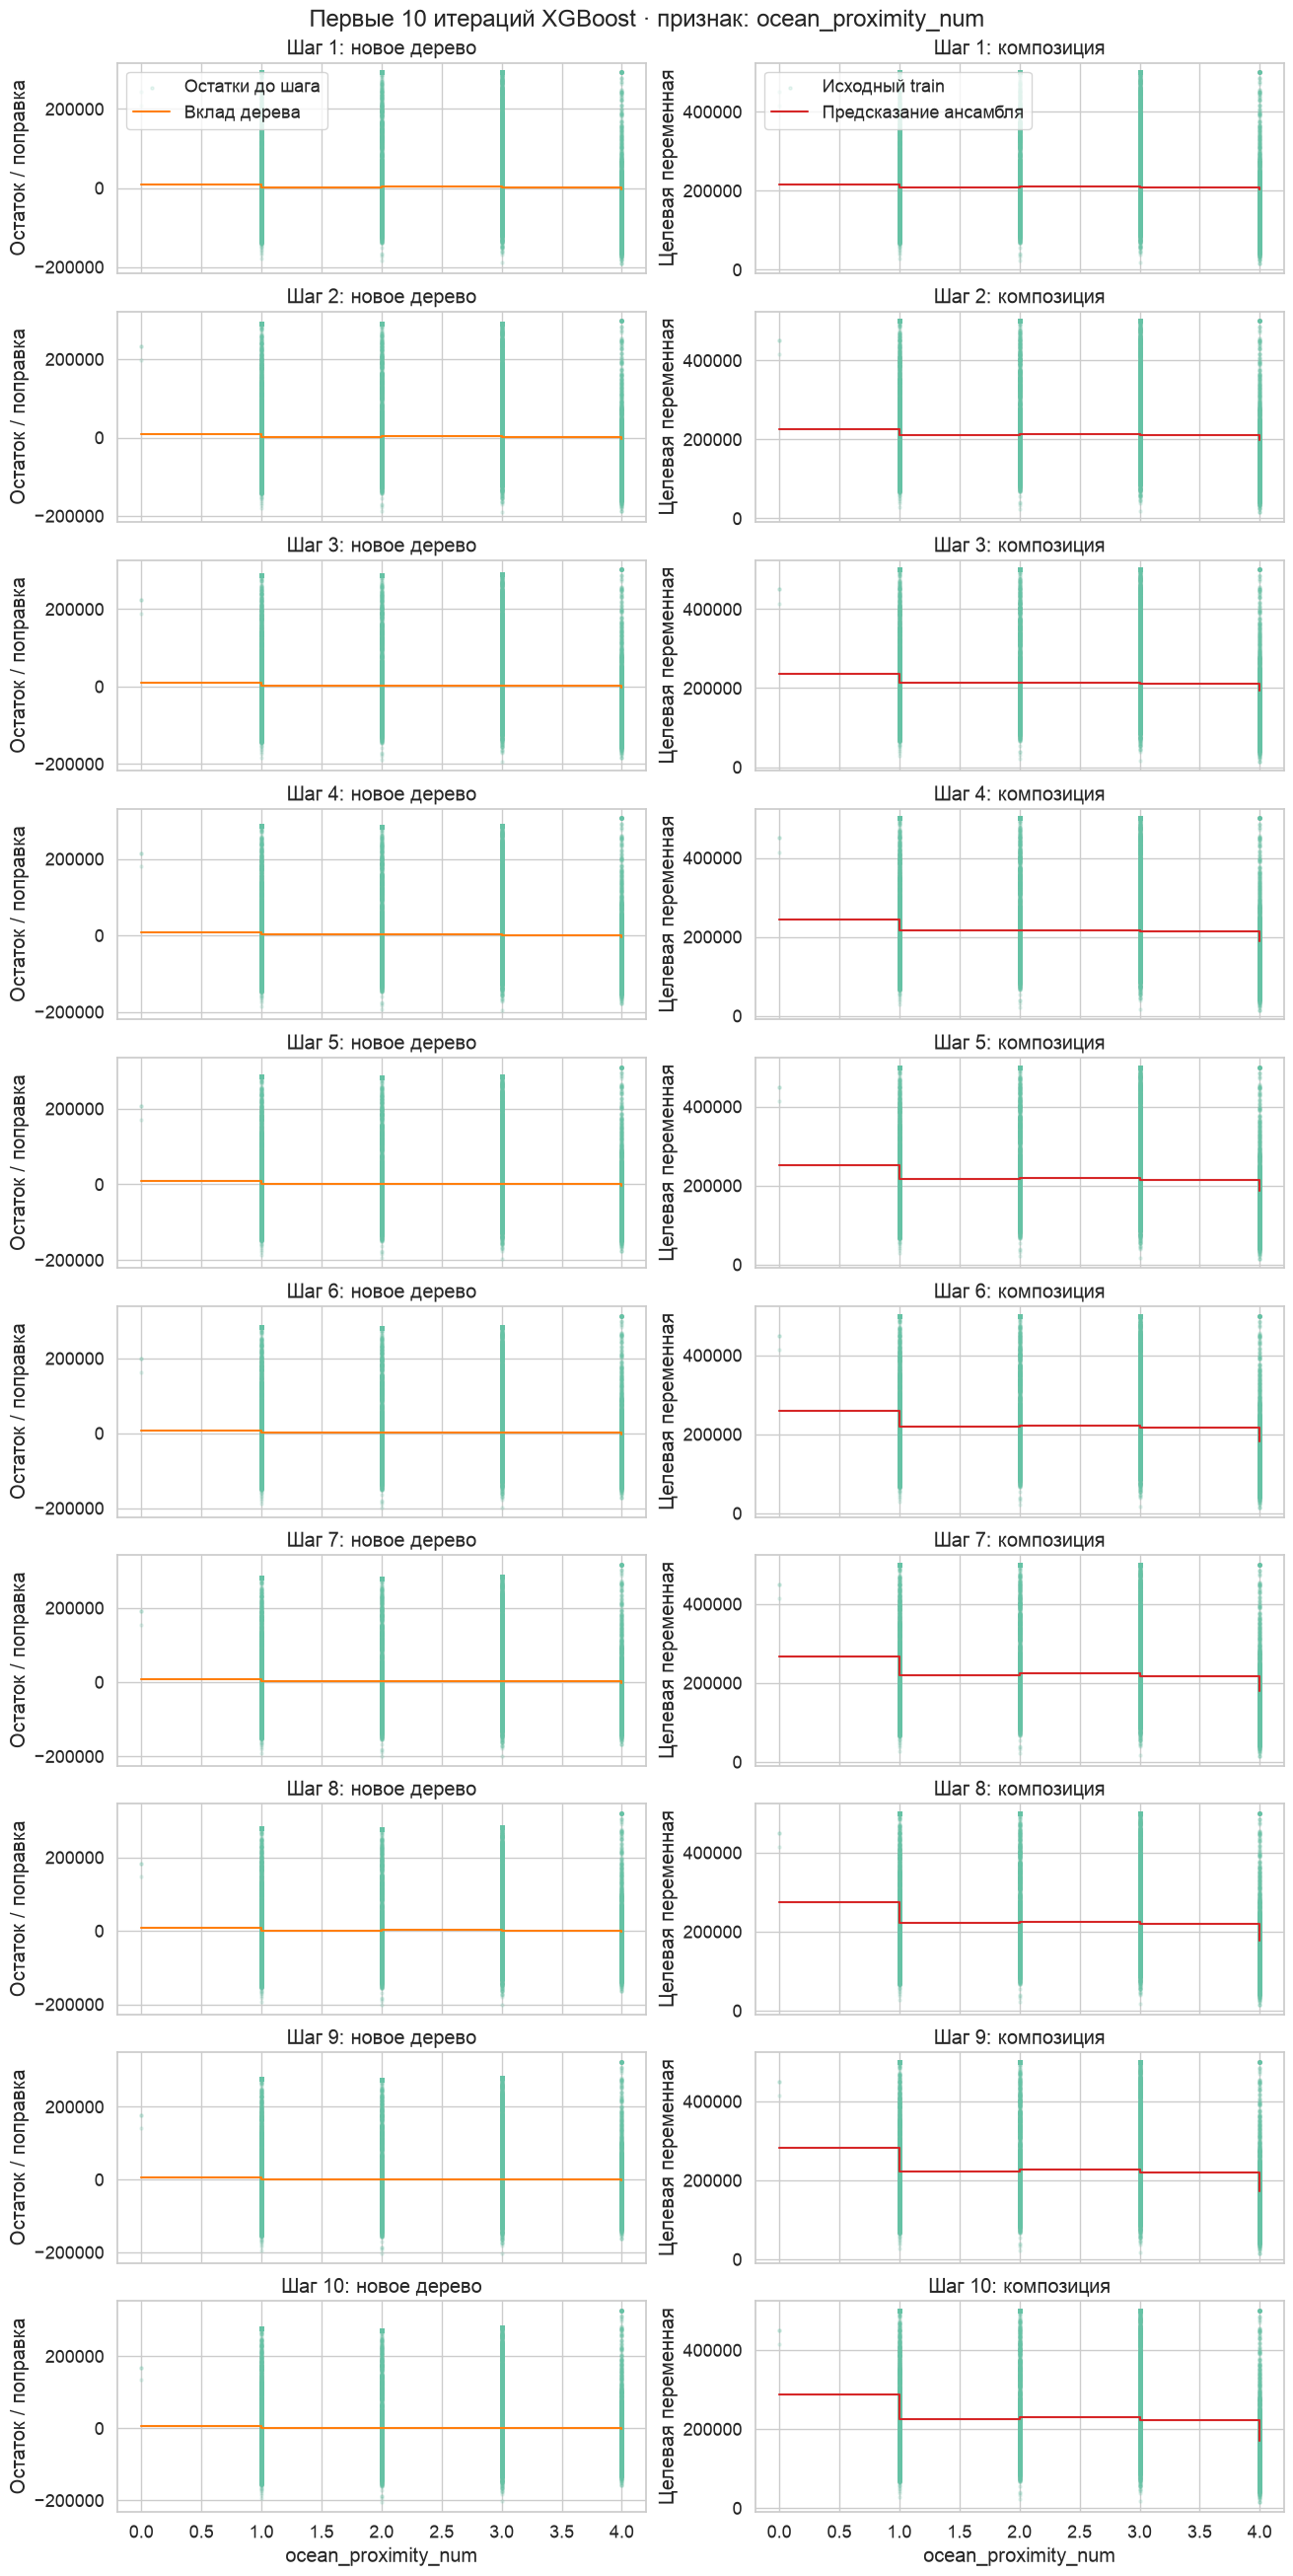

In [23]:
fig, axes = plt.subplots(N_STEPS, 2, figsize=(13, 26), sharex=True, layout="constrained")
fig.suptitle(f"Первые {N_STEPS} итераций XGBoost · признак: {feature}")

for step, (ax_tree, ax_ensemble) in enumerate(axes, start=1):
    current_train = one_feature_xgb.predict(x_train, iteration_range=(0, step))
    current_grid = one_feature_xgb.predict(x_grid, iteration_range=(0, step))
    residuals = y_values - previous_train
    tree_update = current_grid - previous_grid

    ax_tree.scatter(x_train[feature], residuals, s=5, alpha=0.15, label="Остатки до шага")
    ax_tree.step(grid_values, tree_update, where="post", color="tab:orange", label="Вклад дерева")
    ax_tree.set(title=f"Шаг {step}: новое дерево", ylabel="Остаток / поправка")

    ax_ensemble.scatter(x_train[feature], y_values, s=5, alpha=0.15, label="Исходный train")
    ax_ensemble.step(grid_values, current_grid, where="post", color="tab:red", label="Предсказание ансамбля")
    ax_ensemble.set(title=f"Шаг {step}: композиция", ylabel="Целевая переменная")

    if step == 1:
        ax_tree.legend()
        ax_ensemble.legend()

    previous_train, previous_grid = current_train, current_grid

for ax in axes[-1]:
    ax.set_xlabel(str(feature))

plt.show()

Как получается выборка, на которой обучается новая базовая модель в данном случае и в общем случае?

На левых графиках обучающая выборка визуально не меняется -- ее разброс сильно меньше чем смещение, и каждая итерация дерева предсказывает остатки близкие к смещению (к нулю).  
С помощью одного признака, конечно, убрать дисперсию не получится, поэтому в данном случае деревья в основном топчутся на месте.   
Но вообще говоря, каждое новое дерево обучается на остатках от композиции предыдущих деревьев, т.е. `изначальный таргет - прогноз текущей композиции`.

В общем случае обучение устроено чуть сложнее (как было описано в лекции) -- деревья обучаются минимизируя антиградиент функционала в точках предсказания текущей композиции (т.н. псевдоостатки).

**6.** Исследуем, какой вклад вносит каждая отдельная базовая модель в градиентном бустинге.

Для реализуем следующую схему.
* Получите предсказания составляющих базовых моделей, что можно сделать, имея "кумулятивные" предсказания.
* Для каждого значения $t$:
    * замените предсказания базовой модели на случайный шум, дисперсию шума возьмите исходя из дисперсии предсказания данной базовой модели;
    * посчитайте итоговые предсказания модели;
    * оцените качество такого предсказания.
    
Почему такая схема реализует требуемое?  

Ну, мы фактически подменяем одно из деревьев ансамбля случайным шумом с той же дисперсией (ну и средним наверное тоже), не меняя остальные деревья.  
(И делаем так по очереди для всех деревьев).  
То есть "тестируем" что будет с предсказанием, если один из компонент подменить на бессмыслицу.  
Если предсказание ухудшится, то это свидетельствует в пользу того, что подмененное дерево делало что-то полезное.

Реализуйте эту схему и постройте график метрики.

In [28]:
N_REPEATS = 30
rng = np.random.default_rng(RANDOM_STATE)
n_trees = best_xgb.get_booster().num_boosted_rounds()
tree_numbers = np.arange(1, n_trees + 1)

full_prediction = best_xgb.predict(X_test_num).astype(np.float64)
baseline_mse = mean_squared_error(y_test, full_prediction)
test_targets = y_test.to_numpy(dtype=np.float64)
zero_margin = np.zeros(len(X_test_num))
mean_noisy_mse = np.empty(n_trees)

for tree_index in tqdm(range(n_trees), desc="Замена деревьев шумом"):
    contribution = best_xgb.predict(
        X_test_num,
        iteration_range=(tree_index, tree_index + 1),
        base_margin=zero_margin,
    ).astype(np.float64)
    noise = rng.normal(contribution.mean(), contribution.std(), size=(N_REPEATS, len(X_test_num)))
    noisy_predictions = (full_prediction - contribution) + noise
    mean_noisy_mse[tree_index] = np.mean(np.square(noisy_predictions - test_targets))

tree_noise_results = pd.DataFrame(
    {
        "tree": tree_numbers,
        "mse_with_noise": mean_noisy_mse,
        "delta_mse": mean_noisy_mse - baseline_mse,
    }
)

Замена деревьев шумом:   0%|          | 0/1000 [00:00<?, ?it/s]

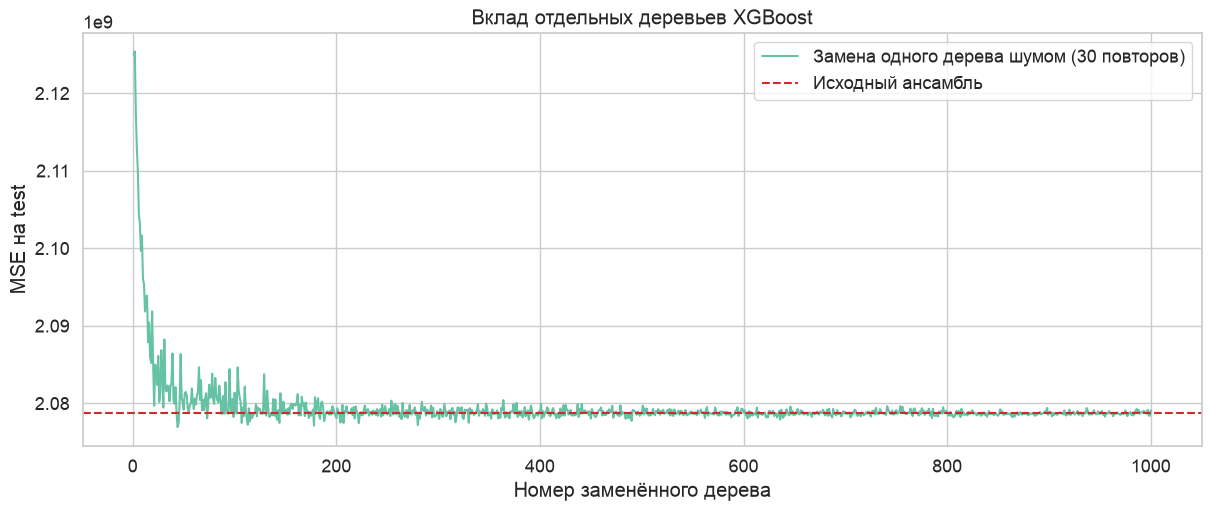

In [27]:
fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
ax.plot(tree_numbers, mean_noisy_mse, label=f"Замена одного дерева шумом ({N_REPEATS} повторов)")
ax.axhline(baseline_mse, color="tab:red", linestyle="--", label="Исходный ансамбль")
ax.set(xlabel="Номер заменённого дерева", ylabel="MSE на test", title="Вклад отдельных деревьев XGBoost")
ax.legend()
plt.show()

Какие можно сделать выводы?

Вполне ожидаемо самый большой вклад вносят ранние деревья, т.к. схема в принципе устроена "последовательно", каждый раз предсказывая остаток от всех остальной композиции, который должен уменьшаться.  

При этом более поздние деревья не совсем бесполезны -- видно что дисперсия (хоть мы и считаем ее таким странным способом по деревьям) уменьшается, т.е. модель становится более устойчивой.

**7.** Обучите градиентный бустинг на решающих деревьях с подобранными ранее гиперпараметрами, у которого в качестве инициализирующей модели используется Rigde-регрессия. 

Для этого
* у класса `GradientBoostingRegressor` можно использовать параметр `init`;
* для XGBoost используйте `.fit(..., base_margin=...)`;
* для CatBoost используйте `Pool(..., baseline=...)`.


Улучшилось ли качество модели на тестовой выборке?

In [34]:
from sklearn.linear_model import Ridge

ridge_model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge_model.fit(X_num_train, y_train)
ridge_train_pred = ridge_model.predict(X_num_train)
ridge_test_pred = ridge_model.predict(X_test_num)

xgb_with_ridge = clone(best_xgb)
xgb_with_ridge.fit(X_num_train, y_train, base_margin=ridge_train_pred)
xgb_with_ridge_pred = xgb_with_ridge.predict(X_test_num, base_margin=ridge_test_pred)

In [36]:
plain_xgb_mse = mean_squared_error(y_test, best_xgb.predict(X_test_num))
ridge_mse = mean_squared_error(y_test, ridge_test_pred)
xgb_with_ridge_mse = mean_squared_error(y_test, xgb_with_ridge_pred)

ridge_init_results = pd.Series(
    {"Ridge": ridge_mse, "XGBoost": plain_xgb_mse, "XGBoost + Ridge": xgb_with_ridge_mse},
    name="MSE на test",
).to_frame()
display(ridge_init_results)

mse_change_pct = 100 * (xgb_with_ridge_mse / plain_xgb_mse - 1)
print(f"Изменение MSE относительно XGBoost: {mse_change_pct:+.2f}%")

,MSE на test
Ridge,4.728180e+09
XGBoost,2.078711e+09
XGBoost + Ridge,2.184941e+09


Изменение MSE относительно XGBoost: +5.11%


Ну, как то не улучшилось...  
Наверное можно было бы ожидать, что Ridge найдет какие то очевидные линейные зависимости, которые сложно описать деревьями, а дальше уже XGBoost "добьет" все остальное.  
Но не вышло...

**8.** Рассмотрим модели смеси градиентного бустинга $\widehat{y}_{gb}$ и случайного леса $\widehat{y}_{rf}$ с оптимальными гиперпараметрами, подобранными ранее, в виде
$$\widehat{y}(x) = w \widehat{y}_{gb}(x) +  (1-w) \widehat{y}_{rf}(x),$$
где $w \in [0, 1]$ &mdash; коэффициент усреднения. Подберите оптимальное значение гиперпараметра $w$ и выведите его. Удалось ли добиться улучшения качества на тестовой выборке?

Это что за полурак-полуёж...

In [38]:
from sklearn.model_selection import KFold, cross_val_predict
cv = KFold(n_splits=7, shuffle=True, random_state=RANDOM_STATE)
xgb_oof = cross_val_predict(best_xgb, X_num_train, y_train, cv=cv, n_jobs=1).astype(np.float64)
rf_oof = cross_val_predict(best_rf, X_num_train, y_train, cv=cv, n_jobs=1).astype(np.float64)

# А-ля МНК для w.
difference = xgb_oof - rf_oof
residual = y_train.to_numpy(dtype=np.float64) - rf_oof
squared_norm = float(difference @ difference)
best_w = float(np.clip((difference @ residual) / squared_norm, 0.0, 1.0)) if squared_norm > 0 else 0.5

xgb_test_pred = best_xgb.predict(X_test_num).astype(np.float64)
rf_test_pred = best_rf.predict(X_test_num).astype(np.float64)
blend_test_pred = best_w * xgb_test_pred + (1 - best_w) * rf_test_pred

xgb_test_mse = mean_squared_error(y_test, xgb_test_pred)
rf_test_mse = mean_squared_error(y_test, rf_test_pred)
blend_test_mse = mean_squared_error(y_test, blend_test_pred)

In [40]:
blend_results = pd.Series(
    {"XGBoost": xgb_test_mse, "Random Forest": rf_test_mse, "Смесь": blend_test_mse},
    name="MSE на test",
).to_frame()
display(blend_results)

print(f"XGBoost: w = {best_w:.4f}; Random Forest: 1 - w = {1 - best_w:.4f}")

,MSE на test
XGBoost,2.078711e+09
Random Forest,4.093151e+09
Смесь,2.078711e+09


XGBoost: w = 1.0000; Random Forest: 1 - w = 0.0000


Ну, $w=1$, т.е. случайный лес мы просто выкинули.  
Честно говоря не понял в чем была задумка, вроде бы бустинг работает лучше леса, вот лес и выкинулся...

На всякий случай проверим визуально на графике...

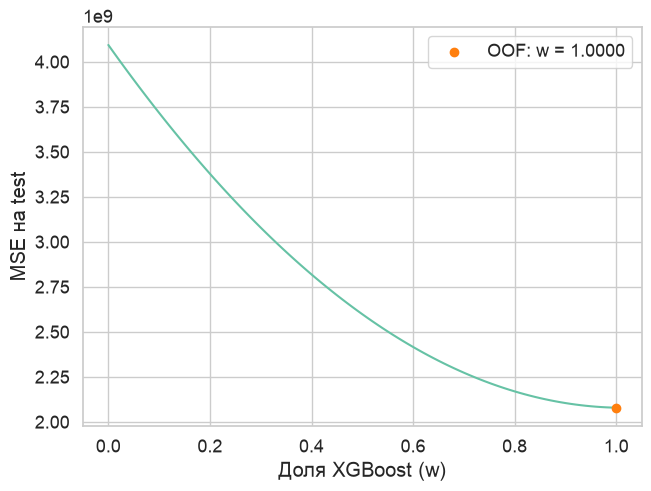

In [41]:
weight_grid = np.linspace(0, 1, 101)
test_mse_curve = [
    mean_squared_error(y_test, weight * xgb_test_pred + (1 - weight) * rf_test_pred) for weight in weight_grid
]

fig, ax = plt.subplots(layout="constrained")
ax.plot(weight_grid, test_mse_curve)
ax.scatter(best_w, blend_test_mse, color="tab:orange", zorder=3, label=f"OOF: w = {best_w:.4f}")
ax.set(xlabel="Доля XGBoost (w)", ylabel="MSE на test")
ax.legend()
plt.show()

**9.** Сделайте итоговые выводы.

**Вывод:**

1. XGBoost на этих данных оказался лучшей моделью. От нее совсем немного отстает sklearn GB, и с еще небольшим отставанием идет catboost. Случайный лес в аутсайдерах.
2. XGBoost также обучался в 3 раза быстрее леса и занимал меньше места. Еще и предсказывал на два порядка быстрее за счет того, что все уже скомпилировано под нативную архитектуру.
3. Самым важным признаком оказался ocean_proximity_num, близость к океану. Но по одному признаку нормальная модель построена не была.
4. Попытка объединить случайный лес с бустингом (ожидаемо) не удалась, как и объединение с Ridge (уже неожиданно).

<div style="box-sizing:border-box;max-width:100%;margin-top:42px;padding:18px 0 4px;border-top:1px solid rgba(127, 127, 127, 0.28);color:inherit;font-size:0.9em;line-height:1.5;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:34px!important;max-width:34px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;">© 2026 команда <a href="https://thetahat.ru/" style="color:inherit;font-weight:750;text-decoration:underline;text-decoration-color:#F13A3F;text-underline-offset:3px;">ThetaHat</a> для курса ML-1 ШАД</div>